In [2]:
import pickle
from pathlib import Path

import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
from jax import config
config.update("jax_enable_x64", True)

import seaborn as sns
import pandas as pd


In [3]:
RESULTS_DIR_TOY = Path("..") / "data" / "results" / "toy_example"
RESULTS_DIR_TCA = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"

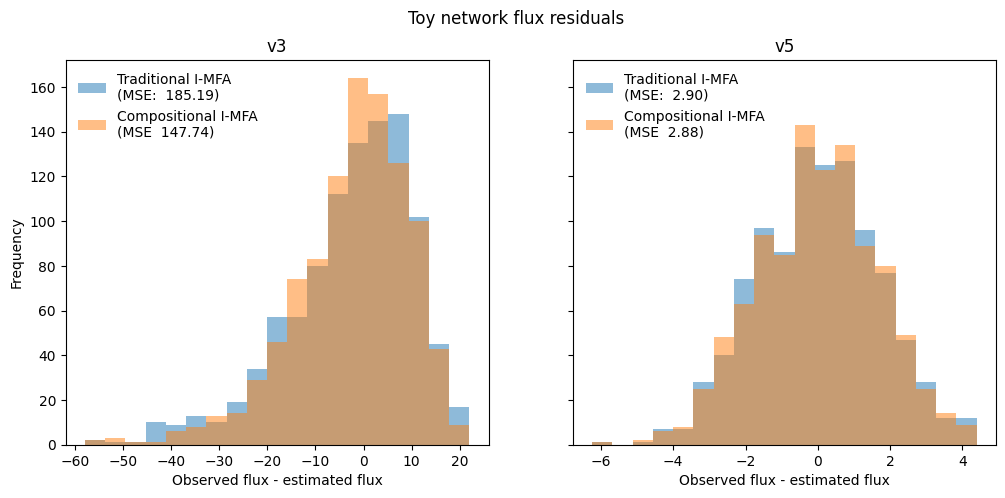

In [4]:
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
true_id_toy = np.load(RESULTS_DIR_TOY / "true_composition.npy")

with open(RESULTS_DIR_TOY / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_toy = pickle.load(f)

resid_trad_toy = (true_flux_toy[None, [2, 4]] - estimated_fluxes_toy["trad"][:, [4,5]])
resid_ilr_toy = (true_flux_toy[None, [2, 4]] - estimated_fluxes_toy["ilr"][:, [4,5]])

mse_trad = (resid_trad_toy ** 2).mean(axis=(0))
mse_ilr = (resid_ilr_toy ** 2).mean(axis=(0))

f, axes = plt.subplots(1, 2, figsize=[12, 5], sharey=True)

for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad_toy[:, i].flatten()
    resid_comp_i = resid_ilr_toy[:, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 20)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {mse_trad[i]: .2f})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i]: .2f})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{3+2*i}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False)
axes[0].set_ylabel("Frequency");

f.suptitle("Toy network flux residuals");
# f.savefig(PLOT_DIR / "flux_residuals_toy_true.png", bbox_inches="tight", dpi=200)

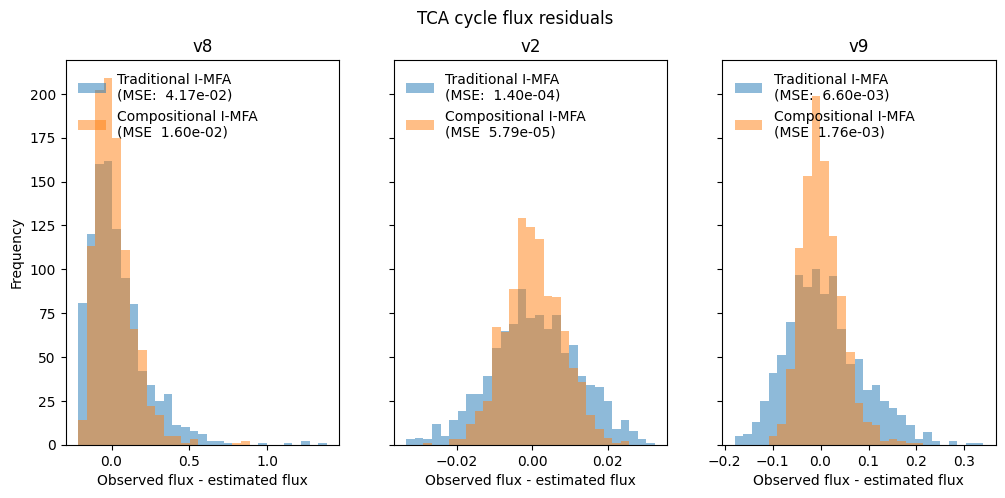

In [5]:
true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True).item()
true_id_tca = np.load(RESULTS_DIR_TCA / "true_composition.npy", allow_pickle=True).item()

with open(RESULTS_DIR_TCA / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_tca = pickle.load(f)

true_ref_tca = np.array([true_flux_tca[k] for k in ["v8", "v2", "v9"]])

resid_trad_tca = estimated_fluxes_tca["trad"][:,:] - true_ref_tca[None, :]
resid_ilr_tca = estimated_fluxes_tca["ilr"][:,:] - true_ref_tca[None, :]

mse_trad = (resid_trad_tca ** 2).mean(axis=(0))
mse_ilr = (resid_ilr_tca ** 2).mean(axis=(0))

f, axes = plt.subplots(1, 3, figsize=[12, 5], sharey=True)
free_flux_numbers = jnp.array([8,2,9])
for (i, ax) in enumerate(axes):
    resid_trad_i = resid_trad_tca[:, i].flatten()
    resid_comp_i = resid_ilr_tca[:, i].flatten()
    xmin = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.001)
    xmax = np.quantile(np.concat([resid_trad_i, resid_comp_i]), 0.999)
    bins = np.linspace(xmin, xmax, 30)
    h_trad = ax.hist(
        resid_trad_i, 
        bins=bins,
        alpha=0.5,
        label=f"Traditional I-MFA\n(MSE: {mse_trad[i]: .2e})" 
    )
    h_ilr = ax.hist(
        resid_comp_i, 
        bins=bins,
        alpha=0.5,
        label=f"Compositional I-MFA\n(MSE {mse_ilr[i]: .2e})" 
    )
    # ax.axvline(true_flux[flux_ix], color="red", label=f"True flux ({true_flux[flux_ix]})")
    ax.set(title=f"v{free_flux_numbers[i]}", xlabel="Observed flux - estimated flux")
    ax.legend(frameon=False, loc="upper left")
axes[0].set_ylabel("Frequency");

f.suptitle("TCA cycle flux residuals");
# f.savefig(PLOT_DIR / "flux_residuals_tca.png", bbox_inches="tight", dpi=200)

In [ ]:
# ── palette ───────────────────────────────────────────────────────────────────
CRIMSON = '#73102A'   # P point
INDIGO  = '#1C0B9C'   # Q point
OLIVE   = '#558C03'   # simplex face
TEAL    = '#038C7F'   # vertices
DIST_E  = "#DB7211"   # Euclidean distance (amber/gold)
DIST_A  = '#9C27B0'   # Aitchison distance (purple)

# Axis colors
A_COLOR = '#CC4400'   # Axis A (deep orange-red)
B_COLOR = '#007700'   # Axis B (forest green)
C_COLOR = '#0044BB'   # Axis C (medium blue)

TRAD  = "#DB7211" 
ILR =  '#038C7F'

/tmp/ipykernel_1215644/2993719567.py:79: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


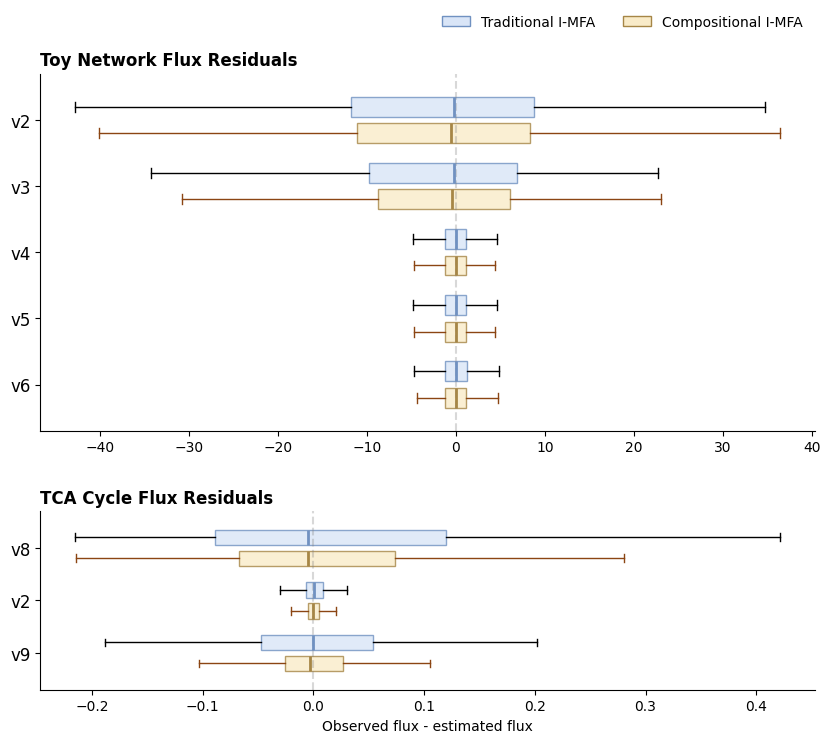

In [113]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# --- 1. DATA LOADING ---
# (Assumes RESULTS_DIR_TOY and RESULTS_DIR_TCA are defined)
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
with open(RESULTS_DIR_TOY / "estimated_fluxes_reference.pkl", "rb") as f:
    est_toy = pickle.load(f)

true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True).item()
with open(RESULTS_DIR_TCA / "estimated_fluxes_reference.pkl", "rb") as f:
    est_tca = pickle.load(f)

# Calculate Residuals
res_trad_toy = (true_flux_toy[None, :] - est_toy["trad"][:, [3,0,4,1,5,2]])
res_comp_toy = (true_flux_toy[None, :] - est_toy["ilr"][:, [3,0,4,1,5,2]])


true_ref_tca = np.array([true_flux_tca[k] for k in ["v8", "v2", "v9"]])
res_trad_tca = est_tca["trad"][:, :] - true_ref_tca[None, :]
res_comp_tca = est_tca["ilr"][:, :] - true_ref_tca[None, :]

# --- 2. PLOTTING ---

# Create two subplots with different heights based on number of variables
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), 
                               gridspec_kw={'height_ratios': [6, 3], 'hspace': 0.3})

def draw_group(ax, trad_data, comp_data, labels):
    positions = np.arange(len(labels))[::-1]
    for i, pos in enumerate(positions):
        # Traditional (Blue)
        ax.boxplot(trad_data[i], vert=False, positions=[pos + 0.2], widths=0.3,
                   patch_artist=True, showfliers=False,
                   boxprops=dict(facecolor='#D9E5F7', color='#7091C1', alpha=0.8),
                   medianprops=dict(color='#7091C1', linewidth=2),
                   whiskerprops=dict(color='black'),
                   capprops=dict(color='black'))
        
        # Compositional (Gold)
        ax.boxplot(comp_data[i], vert=False, positions=[pos - 0.2], widths=0.3,
                   patch_artist=True, showfliers=False,
                   boxprops=dict(facecolor='#F9EBC8', color='#A68646', alpha=0.8),
                   medianprops=dict(color='#A68646', linewidth=2),
                   whiskerprops=dict(color='#8B4513'),
                   capprops=dict(color='#8B4513'))
    
    ax.set_yticks(positions)
    ax.set_yticklabels(labels, fontsize=12)
    ax.axvline(0, color='gray', linestyle='--', alpha=0.3)
    # Remove top/right spines
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

# Top Plot: Toy Network
draw_group(ax1, 
           [res_trad_toy[:, 1], res_trad_toy[:, 2], res_trad_toy[:, 3], res_trad_toy[:, 4], res_trad_toy[:, 5]], 
           [res_comp_toy[:, 1], res_comp_toy[:, 2], res_comp_toy[:, 3], res_comp_toy[:, 4], res_comp_toy[:, 5]], 
           ["v2","v3", "v4", "v5", "v6"])
ax1.set_title("Toy Network Flux Residuals", fontweight='bold', loc='left')

# Bottom Plot: TCA Cycle
draw_group(ax2, 
           [res_trad_tca[:, 0], res_trad_tca[:, 1], res_trad_tca[:, 2]], 
           [res_comp_tca[:, 0], res_comp_tca[:, 1], res_comp_tca[:, 2]], 
           ["v8", "v2", "v9"])
ax2.set_title("TCA Cycle Flux Residuals", fontweight='bold', loc='left')
ax2.set_xlabel("Observed flux - estimated flux")

# Shared Legend
legend_elements = [
    Patch(facecolor='#D9E5F7', edgecolor='#7091C1', label='Traditional I-MFA'),
    Patch(facecolor='#F9EBC8', edgecolor='#A68646', label='Compositional I-MFA')
]
ax1.legend(handles=legend_elements, bbox_to_anchor=(1, 1.2), loc='upper right', ncol=2, frameon=False)

plt.tight_layout()
plt.show()

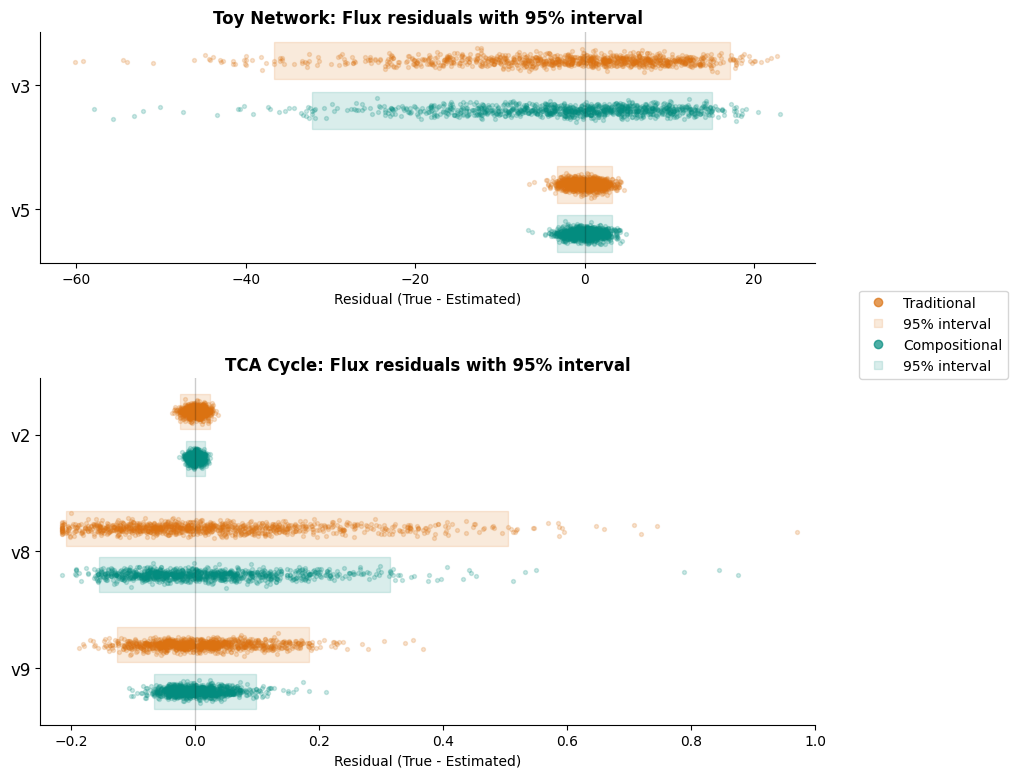

In [117]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

# --- 1. DATA LOADING & RESIDUALS ---
# (Assumes RESULTS_DIR_TOY and RESULTS_DIR_TCA are defined as in previous steps)
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
with open(RESULTS_DIR_TOY / "estimated_fluxes_reference.pkl", "rb") as f:
    est_toy = pickle.load(f)

true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True).item()
with open(RESULTS_DIR_TCA / "estimated_fluxes_reference.pkl", "rb") as f:
    est_tca = pickle.load(f)

res_trad_toy = (true_flux_toy[None, [2, 4]] - est_toy["trad"][:, [4, 5]])
res_comp_toy = (true_flux_toy[None, [2, 4]] - est_toy["ilr"][:, [4, 5]])

true_ref_tca = np.array([true_flux_tca[k] for k in ["v8", "v2", "v9"]])
res_trad_tca = est_tca["trad"][:, :] - true_ref_tca[None, :]
res_comp_tca = est_tca["ilr"][:, :] - true_ref_tca[None, :]

# --- 2. PLOTTING ---

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 9), 
                               gridspec_kw={'height_ratios': [2, 3], 'hspace': 0.4})

def draw_scatter_with_95_interval(ax, trad_data, comp_data, labels):
    positions = np.arange(len(labels))[::-1]
    
    for i, pos in enumerate(positions):
        data_pairs = [
            (trad_data[i], pos + 0.2, TRAD, 'Traditional'),
            (comp_data[i], pos - 0.2, ILR, 'Compositional')
        ]
        
        for data, y_pos, color, label in data_pairs:
            # Calculate 95% Interval (2.5% to 97.5%)
            lower = np.percentile(data, 2.5)
            upper = np.percentile(data, 97.5)
            
            # Draw the 95% Sample Space Box
            rect = Rectangle((lower, y_pos - 0.15), upper - lower, 0.3, 
                             linewidth=1, edgecolor=color, facecolor=color, alpha=0.15)
            ax.add_patch(rect)
            
            # Draw Jittered Scatter Points
            jitter = np.random.normal(y_pos, 0.03, size=len(data))
            ax.scatter(data, jitter, color=color, s=8, alpha=0.20, label=label if i==0 else "")
            

    ax.set_yticks(positions)
    ax.set_yticklabels(labels, fontsize=12)
    ax.axvline(0, color='black', linestyle='-', alpha=0.2, lw=1)
    
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

# Render Toy Network
draw_scatter_with_95_interval(ax1, 
                              [res_trad_toy[:, 0], res_trad_toy[:, 1]], 
                              [res_comp_toy[:, 0], res_comp_toy[:, 1]], 
                              ["v3", "v5"])
ax1.set_title("Toy Network: Flux residuals with 95% interval", fontweight='bold')
ax1.set_xlabel("Residual (True - Estimated)")

# Render TCA Cycle
draw_scatter_with_95_interval(ax2, 
                              [res_trad_tca[:, 1], res_trad_tca[:, 0], res_trad_tca[:, 2]], 
                              [res_comp_tca[:, 1], res_comp_tca[:, 0], res_comp_tca[:, 2]], 
                              ["v2", "v8", "v9"])
ax2.set_xlim(-0.25,1)
ax2.set_title("TCA Cycle: Flux residuals with 95% interval", fontweight='bold')
ax2.set_xlabel("Residual (True - Estimated)")

# Unified Legend
# ax1.legend(loc='upper right', frameon=False, bbox_to_anchor=(1.1, 1.2), ncol=2)

# Custom legend
custom_marker = [
    Line2D([0], [0], color=TRAD, marker="o", linestyle="", markersize=6, alpha = 0.7),
    Line2D([0], [0], color=TRAD, marker="s", linestyle="", markersize=6, alpha = 0.15),
    Line2D([0], [0], color=ILR, marker="o", linestyle="", markersize=6, alpha = 0.7),
    Line2D([0], [0], color=ILR, marker="s", linestyle="", markersize=6, alpha = 0.15),
]
fig.legend(custom_marker, ["Traditional", "95% interval", "Compositional", "95% interval"], fontsize=10, loc="outside right upper", bbox_to_anchor=(1.1,0.6))

plt.show()

Caption: 
Flux residuals 
For TCA cycle the plot is cuttet at 1, not showing 6 outliers for TCA cycle v8 traditional I-MFA

In [128]:
count = jnp.sum(res_trad_tca[:,0] > 1)
count

Array(6, dtype=int64)

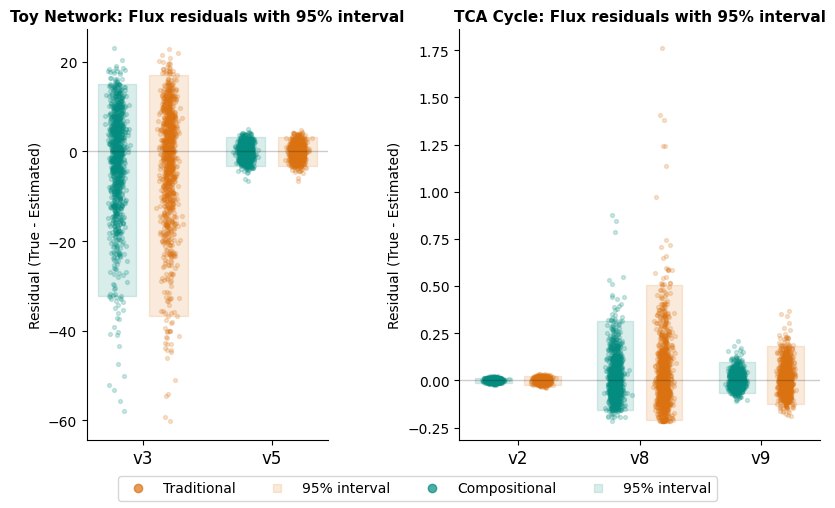

In [108]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

# --- 1. DATA LOADING & RESIDUALS ---
# (Assumes RESULTS_DIR_TOY and RESULTS_DIR_TCA are defined as in previous steps)
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
with open(RESULTS_DIR_TOY / "estimated_fluxes_reference.pkl", "rb") as f:
    est_toy = pickle.load(f)

true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True).item()
with open(RESULTS_DIR_TCA / "estimated_fluxes_reference.pkl", "rb") as f:
    est_tca = pickle.load(f)

res_trad_toy = (true_flux_toy[None, [2, 4]] - est_toy["trad"][:, [4, 5]])
res_comp_toy = (true_flux_toy[None, [2, 4]] - est_toy["ilr"][:, [4, 5]])

true_ref_tca = np.array([true_flux_tca[k] for k in ["v8", "v2", "v9"]])
res_trad_tca = est_tca["trad"][:, :] - true_ref_tca[None, :]
res_comp_tca = est_tca["ilr"][:, :] - true_ref_tca[None, :]

# --- 2. PLOTTING ---

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 5), 
                               gridspec_kw={'width_ratios': [2, 3], 'wspace': 0.15}, layout="constrained")

def draw_scatter_with_95_interval(ax, trad_data, comp_data, labels):
    positions = np.arange(len(labels))
    
    for i, pos in enumerate(positions):
        data_pairs = [
            (trad_data[i], pos + 0.2, TRAD, 'Traditional'),
            (comp_data[i], pos - 0.2, ILR, 'Compositional')
        ]
        
        for data, y_pos, color, label in data_pairs:
            # Calculate 95% Interval (2.5% to 97.5%)
            lower = np.percentile(data, 2.5)
            upper = np.percentile(data, 97.5)
            
            # Draw the 95% Sample Space Box
            rect = Rectangle((y_pos - 0.15, lower), 0.3, upper - lower, 
                             linewidth=1, edgecolor=color, facecolor=color, alpha=0.15)
            ax.add_patch(rect)
            
            # Draw Jittered Scatter Points
            jitter = np.random.normal(y_pos, 0.03, size=len(data))
            ax.scatter(jitter, data, color=color, s=8, alpha=0.20, label=label if i==0 else "")
            

    ax.set_xticks(positions)
    ax.set_xticklabels(labels, fontsize=12)
    ax.axhline(0, color='black', linestyle='-', alpha=0.2, lw=1)
    
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

# Render Toy Network
draw_scatter_with_95_interval(ax1, 
                              [res_trad_toy[:, 0], res_trad_toy[:, 1]], 
                              [res_comp_toy[:, 0], res_comp_toy[:, 1]], 
                              ["v3", "v5"])
ax1.set_title("Toy Network: Flux residuals with 95% interval", fontweight='bold', fontsize=11)
ax1.set_ylabel("Residual (True - Estimated)")

# Render TCA Cycle
draw_scatter_with_95_interval(ax2, 
                              [res_trad_tca[:, 1], res_trad_tca[:, 0], res_trad_tca[:, 2]], 
                              [res_comp_tca[:, 1], res_comp_tca[:, 0], res_comp_tca[:, 2]], 
                              ["v2", "v8", "v9"])
ax2.set_title("TCA Cycle: Flux residuals with 95% interval", fontweight='bold', fontsize=11)
ax2.set_ylabel("Residual (True - Estimated)")

# Unified Legend
# ax1.legend(loc='upper right', frameon=False, bbox_to_anchor=(1.1, 1.2), ncol=2)

# Custom legend
custom_marker = [
    Line2D([0], [0], color=TRAD, marker="o", linestyle="", markersize=6, alpha = 0.7),
    Line2D([0], [0], color=TRAD, marker="s", linestyle="", markersize=6, alpha = 0.15),
    Line2D([0], [0], color=ILR, marker="o", linestyle="", markersize=6, alpha = 0.7),
    Line2D([0], [0], color=ILR, marker="s", linestyle="", markersize=6, alpha = 0.15),
]
fig.legend(custom_marker, ["Traditional", "95% interval", "Compositional", "95% interval"], fontsize=10, ncol=4, loc="outside lower center") #bbox_to_anchor=(1.1,0.6)

plt.show()